# Visualize Model Predictions

This notebook loads a trained model and visualizes its predictions on a new sample.

In [1]:
import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import napari
from scipy.interpolate import griddata
from pathlib import Path

from plot_utils_era5 import *

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities
from plot_utilities import plot_results_napari, plot_results_matplotlib

# Device setup
device = setup_device()
print(f'Using device: {device}')

from sklearn.decomposition import PCA
import time
from IPython.display import display
import plotly.express as px

Using device: mps


In [2]:
def load_model(id:str, model_type:str='random_crop'):
    model_path = project_root / 'ERA5' / 'trained_models' / model_type / id
    with open(model_path, 'r') as f:
        config = json.load(f)
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)
    return model
    

In [20]:
os.system("rsync -r springfield:~/new/NOFE/ERA5/trained_models/* ../trained_models/")

** WARNING: connection is not using a post-quantum key exchange algorithm.
** This session may be vulnerable to "store now, decrypt later" attacks.
** The server may need to be upgraded. See https://openssh.com/pq.html


0

In [6]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator
#from utilities_era5 import ERA5_Graph_Generator_perSampleNorm as Data_Generator_old
from utilities_era5 import ERA5_Graph_Generator as Data_Generator



# Paths
trained_models_path = project_root / 'ERA5' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'ERA5' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if (Path(f).suffix == ".pth") and ('adamw' in f):
        print(f'[{i}] {f}')


Available models:

[40] test1_model5_median_tkernel_adamw_2026-04-28_t08-30-25.pth
[67] test1_model1_median_tkernel_adamw_2026-04-28_t08-44-05.pth
[68] test1_model1_median_tkernel_adamw_2026-04-28_t08-30-25.pth


## 2. Load Model and Configuration

In [7]:
# Set model ID
model_id = 'test1_model1_median_tkernel_adamw_2026-04-28_t08-44-05'
# model_id = files[19]#'reg_medium_woPos_deep6-regular-2026-04-13_t18-58-47'



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  model_config_path: ERA5/configurations/regular/model_configs/testmodel1_w8_kw32_d3.json
  dataset_id: dataset_reg_fixcrop_median_woPos_tkernel
  dataset_path: ERA5/datasets/regular
  learning_rate: 0.0005
  scheduler_step: 4
  scheduler_gamma: 0.6
  epochs: 25
  random_seed: 42
  use_gradient_clipping: False
  track_gradients: True
  checkpoint_every: 5
  width: 8
  ker_width: 32
  depth: 3
  node_features: 11
  edge_attr: 7
  out_width: 3
  data_folder_path: ../data/
  dataset_save_path: ../datasets/regular/
  lat_min: 30
  lat_max: 75
  lon_min: -12
  lon_max: 33
  N_min: 500
  N_max: 10000
  k: 10
  perplexity: 10
  sampling_method: random
  train_date_start_end: ['2018-01-01', '2018-12-31']
  test_date_start_end: ['2019-01-01', '2019-01-31']
  train_samples_per_date: 10
  test_samples_per_date: 5
  feature_mode: channel_only
  sigma_method: global_median
  vars: ['w', 'v', 'z', 'q', 'r', 't', 'd', 'o3', 'pv', 'u', 'vo']
\Training completed 6 epochs
Final training l

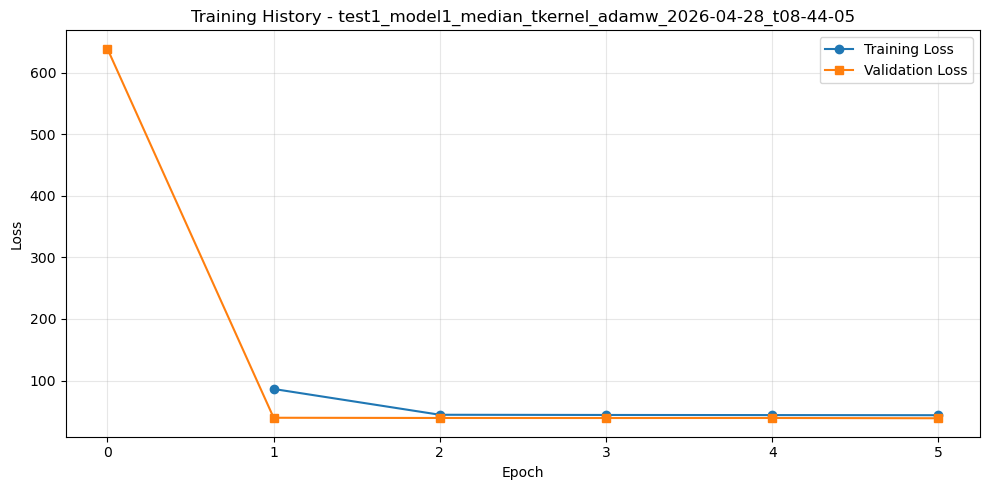

In [8]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]
#N = config["N"]
k = config["k"]
perplexity = config["perplexity"]
sampling_method = config["sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
vars = config["vars"]


In [10]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: test1_model1_median_tkernel_adamw_2026-04-28_t08-44-05
Total parameters: 3,619


## 3. Create New Sample

Use the same functionality as dataset creation to generate a single sample.

In [15]:
date = "2019-01-15"

#bbox = lon_min, lat_min, lon_max, lat_max
bbox = -12, 30, 33, 75
#Generator = Data_Generator_old(data_path)
Generator = Data_Generator(data_path)
Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
print(f'total points available: {Generator.da.shape[1]*Generator.da.shape[2]}')

N=30000
print('generate data')
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode, sigma_method=config['sigma_method'])
sample = graph.to(device)

locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})

total points available: 32761
generate data


In [16]:
print('predict results')
output = model(sample).detach().cpu().numpy()

predict results


---
Plot

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.011750699845428309..1.0115552708215707].


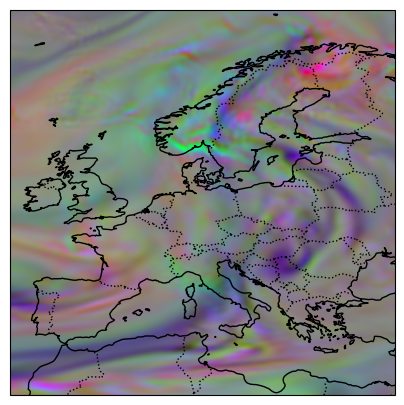

In [17]:
locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})

res_model = pd.DataFrame(
    {
        "x1": output[:, 0],
        "x2": output[:, 1],
        "x3": output[:, 2],
    }
)
res_model = pd.concat([locations, res_model], axis=1)

figsize = (5, 5)
fig = rgb(res_model, figsize=figsize)
#fig = rgb_scale(res_model, percentile=1, figsize=figsize)

In [14]:
fig_3d = px.scatter_3d(
        res_model,
        x="x1",
        y="x2",
        z="x3",
        color="x3",  # optional coloring
        title=f"3D Scatter: {model_id}"
    )
fig_3d.update_traces(marker=dict(size=1)) 
fig_3d.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.007820441727399386..0.9316727552384435].


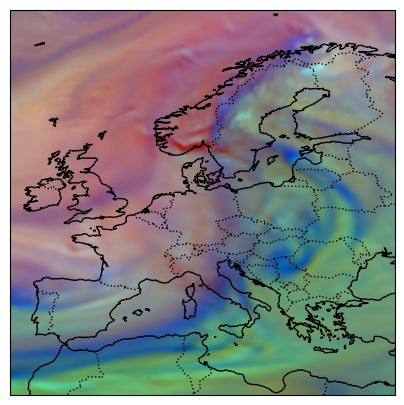

In [18]:

# example input (replace with your array)
X = sample.x.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)

locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})


# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations, res_pca], axis=1)

fig = rgb(res_pca, figsize=figsize)

In [19]:
fig_3d = px.scatter_3d(
        res_pca,
        x="x1",
        y="x2",
        z="x3",
        color="x3",  # optional coloring
        title=f"3D Scatter: PCA"
    )
fig_3d.update_traces(marker=dict(size=1)) 
fig_3d.show()

## Compare models

In [19]:
from IPython.display import display
import time

In [21]:
for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')

[0] testmodel8_w64_kw128_d6-regular-2026-04-14_t21-23-08.pth
[1] testmodel8_w64_kw128_d6-regular-2026-04-14_t14-25-44.pth
[2] testmodel7_w64_kw128_d3-regular-2026-04-14_t20-14-16.pth
[3] testmodel7_w64_kw128_d3-regular-2026-04-14_t13-56-50.pth
[4] testmodel6_w64_kw32_d6-regular-2026-04-14_t21-35-53.pth
[5] testmodel6_w64_kw32_d6-regular-2026-04-14_t13-45-23.pth
[6] testmodel5_w64_kw32_d3-regular-2026-04-14_t20-59-30.pth
[7] testmodel5_w64_kw32_d3-regular-2026-04-14_t13-23-20.pth
[8] testmodel4_w8_kw128_d6-regular-2026-04-14_t20-14-16.pth
[9] testmodel4_w8_kw128_d6-regular-2026-04-14_t13-00-13.pth
[10] testmodel3_w8_kw128_d3-regular-2026-04-14_t21-21-07.pth
[11] testmodel3_w8_kw128_d3-regular-2026-04-14_t13-40-33.pth
[12] testmodel2_w8_kw32_d6-regular-2026-04-14_t20-43-00.pth
[13] testmodel2_w8_kw32_d6-regular-2026-04-14_t13-17-37.pth
[14] testmodel1_w8_kw32_d3-regular-2026-04-15_t10-12-45.pth
[15] testmodel1_w8_kw32_d3-regular-2026-04-14_t20-14-16.pth
[16] testmodel1_w8_kw32_d3-regular

testmodel8_w64_kw128_d6-regular-2026-04-14_t14-25-44
Final training loss: 185.8657	Final validation loss: 175.8312


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0638459115109398..1.041931585431358].


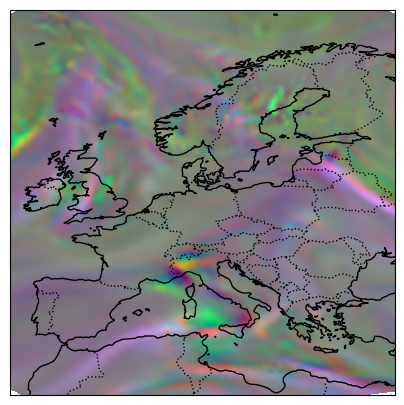

testmodel7_w64_kw128_d3-regular-2026-04-14_t13-56-50
Final training loss: 190.3551	Final validation loss: 179.9484


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.009014581353591638..1.0110060883983742].


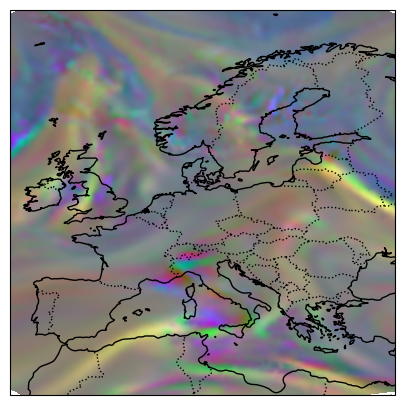

testmodel6_w64_kw32_d6-regular-2026-04-14_t13-45-23
Final training loss: 190.6796	Final validation loss: 178.7475


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.003970069784418599..1.0032498743400815].


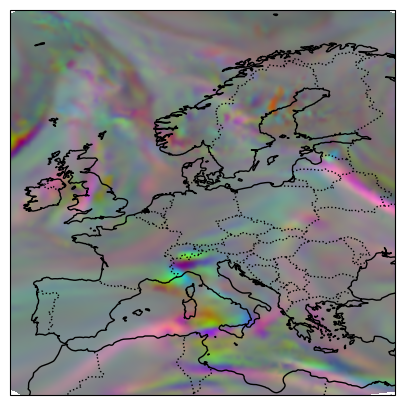

testmodel5_w64_kw32_d3-regular-2026-04-14_t13-23-20
Final training loss: 194.1328	Final validation loss: 182.5275


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.007388132639085313..1.0127685335011543].


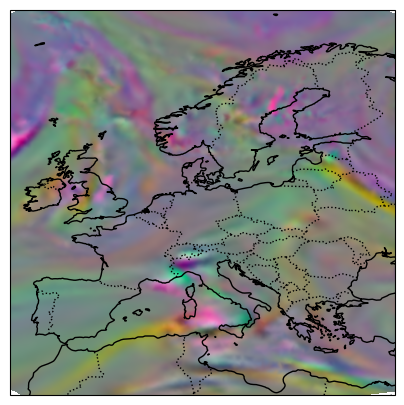

testmodel4_w8_kw128_d6-regular-2026-04-14_t13-00-13
Final training loss: 314.8828	Final validation loss: 295.1972


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0333025466375585..1.0050448837066865].


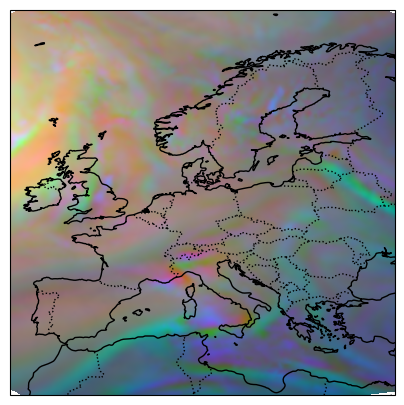

testmodel3_w8_kw128_d3-regular-2026-04-14_t13-40-33
Final training loss: 232.8521	Final validation loss: 213.2073


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.02752282145609297..1.0249411442025513].


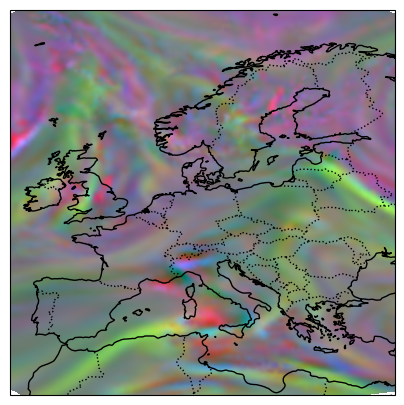

testmodel2_w8_kw32_d6-regular-2026-04-14_t13-17-37
Final training loss: 471.9758	Final validation loss: 434.5674


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0014958290241190028..1.0000035466212804].


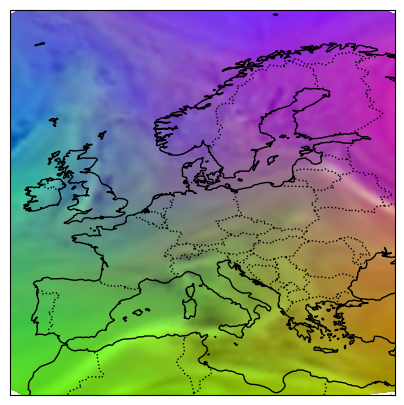

testmodel1_w8_kw32_d3-regular-2026-04-14_t20-14-16
Final training loss: 308.0991	Final validation loss: 321.6614


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.020227295871316168..0.9197939222278666].


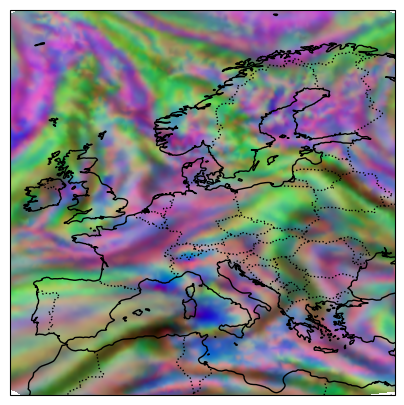

PCA:


NameError: name 'PCA' is not defined

In [30]:
for i in [1,3,5,7,9,11,13,15]:
    model_id = files[i]#'reg_medium_woPos_deep6-regular-2026-04-13_t18-58-47'
    if model_id.endswith('.pth'):
        model_id = model_id[:-4]
    loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')
    print(model_id)
    print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}', end='\t')
    print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')
    # ---------------------------------------------------------------------------

    # Load full configuration (includes model, dataset, and training configs)
    config_path = f'{training_logs_path}/configs/{model_id}.json'
    with open(config_path, 'r') as f:
        config = json.load(f)
        
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)

    # Load trained weights
    model_path = f'{trained_models_path}/{model_id}.pth'
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    
    output = model(sample).detach().cpu().numpy()
    
    res_model = pd.DataFrame(
        {
            "x1": output[:, 0],
            "x2": output[:, 1],
            "x3": output[:, 2],
        }
    )
    res_model = pd.concat([locations, res_model], axis=1)

    figsize = (5, 5)
    fig = rgb(res_model, figsize=figsize)
    display(fig)
    plt.close(fig)
    time.sleep(2)

print('PCA:')
# example input (replace with your array)
X = sample.x.detach().cpu().numpy() # shape: (samples, features)
# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)
locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})
# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations, res_pca], axis=1)
fig = rgb(res_pca, figsize=figsize)    

In [41]:
import pandas as pd
import json
import torch
import matplotlib.pyplot as plt
import plotly.express as px
import time
from IPython.display import display

# Loop
for i in [1,3,5,7,9,11,13,15]:
    model_id = files[i]
    if model_id.endswith('.pth'):
        model_id = model_id[:-4]

    loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')
    print(model_id)
    print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}', end='\t')
    print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

    # ---------------------------------------------------------------------------
    # Load config
    config_path = f'{training_logs_path}/configs/{model_id}.json'
    with open(config_path, 'r') as f:
        config = json.load(f)

    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)

    # Load weights
    model_path = f'{trained_models_path}/{model_id}.pth'
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    # Forward pass
    output = model(sample).detach().cpu().numpy()

    # DataFrame
    res_model = pd.DataFrame({
        "x1": output[:, 0],
        "x2": output[:, 1],
        "x3": output[:, 2],
    })
    res_model = pd.concat([locations, res_model], axis=1)

    # ---------------------------------------------------------------------------
    '''
    # 1. Your existing plot
    figsize = (5, 5)
    fig = rgb(res_model, figsize=figsize)
    display(fig)
    plt.close(fig)
    '''
    
    # ---------------------------------------------------------------------------
    # 2. NEW: Interactive 3D scatter
    fig_3d = px.scatter_3d(
        res_model,
        x="x1",
        y="x2",
        z="x3",
        color="x3",  # optional coloring
        title=f"3D Scatter: {model_id}"
    )
    fig_3d.update_traces(marker=dict(size=1)) 
    fig_3d.show()

    time.sleep(2)

testmodel8_w64_kw128_d6-regular-2026-04-14_t14-25-44
Final training loss: 185.8657	Final validation loss: 175.8312


testmodel7_w64_kw128_d3-regular-2026-04-14_t13-56-50
Final training loss: 190.3551	Final validation loss: 179.9484


testmodel6_w64_kw32_d6-regular-2026-04-14_t13-45-23
Final training loss: 190.6796	Final validation loss: 178.7475


testmodel5_w64_kw32_d3-regular-2026-04-14_t13-23-20
Final training loss: 194.1328	Final validation loss: 182.5275


testmodel4_w8_kw128_d6-regular-2026-04-14_t13-00-13
Final training loss: 314.8828	Final validation loss: 295.1972


testmodel3_w8_kw128_d3-regular-2026-04-14_t13-40-33
Final training loss: 232.8521	Final validation loss: 213.2073


testmodel2_w8_kw32_d6-regular-2026-04-14_t13-17-37
Final training loss: 471.9758	Final validation loss: 434.5674


testmodel1_w8_kw32_d3-regular-2026-04-14_t20-14-16
Final training loss: 308.0991	Final validation loss: 321.6614


testmodel8_w64_kw128_d6-regular-2026-04-14_t21-23-08
Final training loss: 199.4481	Final validation loss: 212.5081


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.034521110376572794..1.0090112722081241].


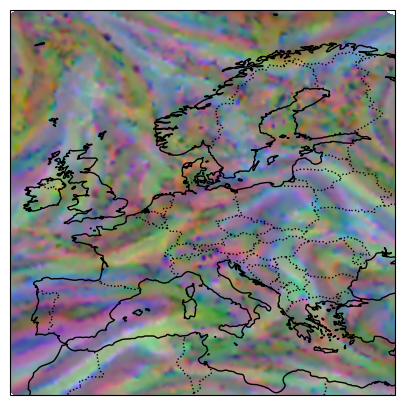

testmodel7_w64_kw128_d3-regular-2026-04-14_t20-14-16
Final training loss: 207.0570	Final validation loss: 221.5328


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.05931649883492561..1.0284674129341669].


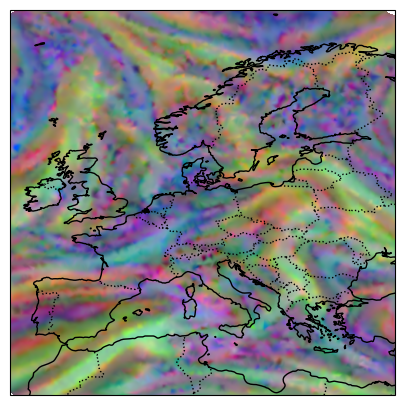

testmodel6_w64_kw32_d6-regular-2026-04-14_t21-35-53
Final training loss: 209.0087	Final validation loss: 222.7864


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.09134333660153605..1.0090552711023881].


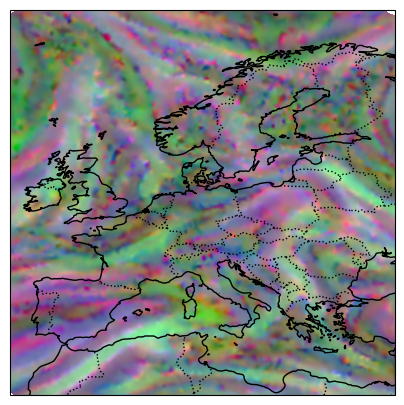

testmodel5_w64_kw32_d3-regular-2026-04-14_t20-59-30
Final training loss: 212.1324	Final validation loss: 225.1642


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0395989091422471..1.0443476441747381].


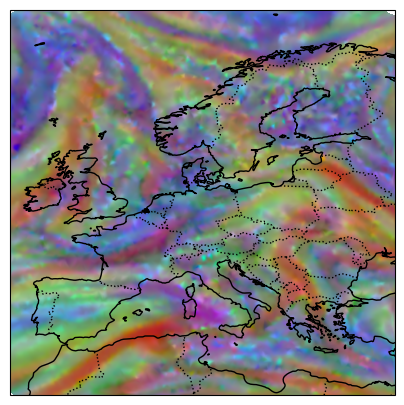

testmodel4_w8_kw128_d6-regular-2026-04-14_t20-14-16
Final training loss: 394.6613	Final validation loss: 414.8211


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.06424328461851307..1.0036301415645625].


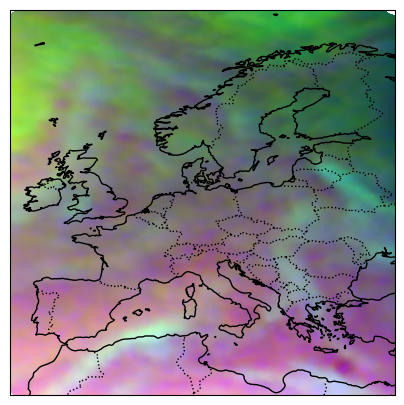

testmodel3_w8_kw128_d3-regular-2026-04-14_t21-21-07
Final training loss: 344.9163	Final validation loss: 363.1126


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.004354298888771314..1.0449501577191245].


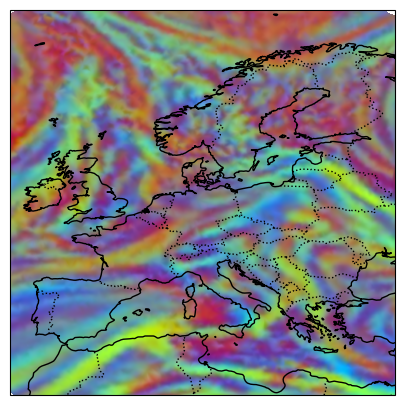

testmodel2_w8_kw32_d6-regular-2026-04-14_t20-43-00
Final training loss: 337.2316	Final validation loss: 348.7274


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008996786130142334..0.9990335976213216].


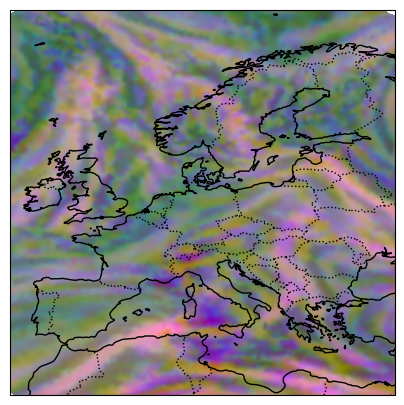

testmodel1_w8_kw32_d3-regular-2026-04-15_t10-12-45
Final training loss: 235.4367	Final validation loss: 238.4050


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.01585578946108428..1.0064914030984544].


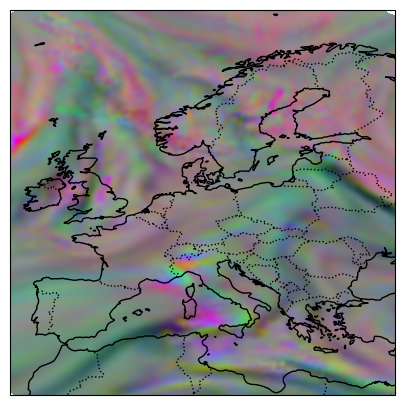

PCA:


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.002312617099457933..1.000007757795477].


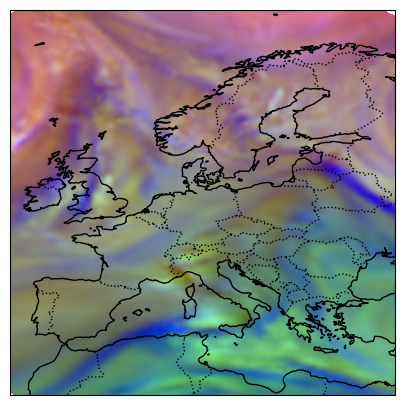

In [45]:
for i in [0,2,4,6,8,10,12,14]:
    model_id = files[i]#'reg_medium_woPos_deep6-regular-2026-04-13_t18-58-47'
    if model_id.endswith('.pth'):
        model_id = model_id[:-4]
    loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')
    print(model_id)
    print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}', end='\t')
    print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')
    # ---------------------------------------------------------------------------


    # Load full configuration (includes model, dataset, and training configs)
    config_path = f'{training_logs_path}/configs/{model_id}.json'
    with open(config_path, 'r') as f:
        config = json.load(f)
        
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)

    # Load trained weights
    model_path = f'{trained_models_path}/{model_id}.pth'
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    
    output = model(sample).detach().cpu().numpy()
    
    res_model = pd.DataFrame(
        {
            "x1": output[:, 0],
            "x2": output[:, 1],
            "x3": output[:, 2],
        }
    )
    res_model = pd.concat([locations, res_model], axis=1)

    figsize = (5, 5)
    fig = rgb(res_model, figsize=figsize)
    display(fig)
    plt.close(fig)
    time.sleep(2)

print('PCA:')
# example input (replace with your array)
X = sample.x.detach().cpu().numpy() # shape: (samples, features)
# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)
locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})
# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations, res_pca], axis=1)
fig = rgb(res_pca, figsize=figsize)    

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.01585722925810123..1.013176198762613].


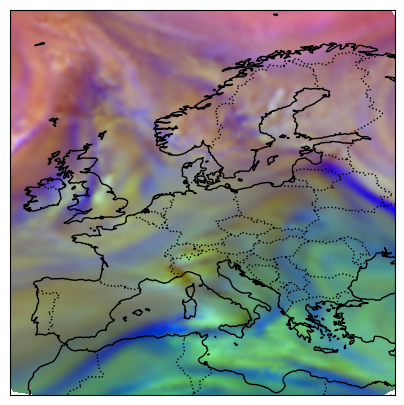

In [14]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# example input (replace with your array)
X = sample.x.detach().cpu().numpy() # shape: (samples, features)

# apply PCA to reduce to 3 dimensions
pca = PCA(n_components=3)
X_reduced = pca.fit_transform(X)

locations = pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]})


# create pandas DataFrame
res_pca= pd.DataFrame(X_reduced, columns=["x1", "x2", "x3"])
res_pca = pd.concat([locations, res_pca], axis=1)

fig = rgb(res_pca, figsize=figsize)